In [1]:
import sys
sys.path.append("..")
from data_reader import DataReader

data_reader = DataReader()
raw, channels, events = data_reader.read_data(
    subject="101",
    duration=60.0,
)

from preprocess import Preprocessor

preprocessor = Preprocessor(raw, 2)
preprocessor.run_pipeline(use_filter=True, use_autoreject=False, use_ica=False)

events_arr = preprocessor.events_arr
event_dict = preprocessor.event_dict

None
Arbeitsverzeichnis: /home/bened/bachelor-thesis/notebooks/BunDLe-Net/notebooks
Datenverzeichnis: /home/bened/bachelor-thesis/data/raw/ds005363-download
Lese BrainVision-Aufnahme ein: /home/bened/bachelor-thesis/data/raw/ds005363-download/sub-101/ses-01/eeg/sub-101_ses-01_task-objrecog_eeg.vhdr
Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 1 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Filter length: 3301 samples (3.301 s)

Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.019

/tmp/ipykernel_22336/748382188.py:2: RuntimeWarning: More events than default colors available. You should pass a list of unique colors.
  fig = mne.viz.plot_events(


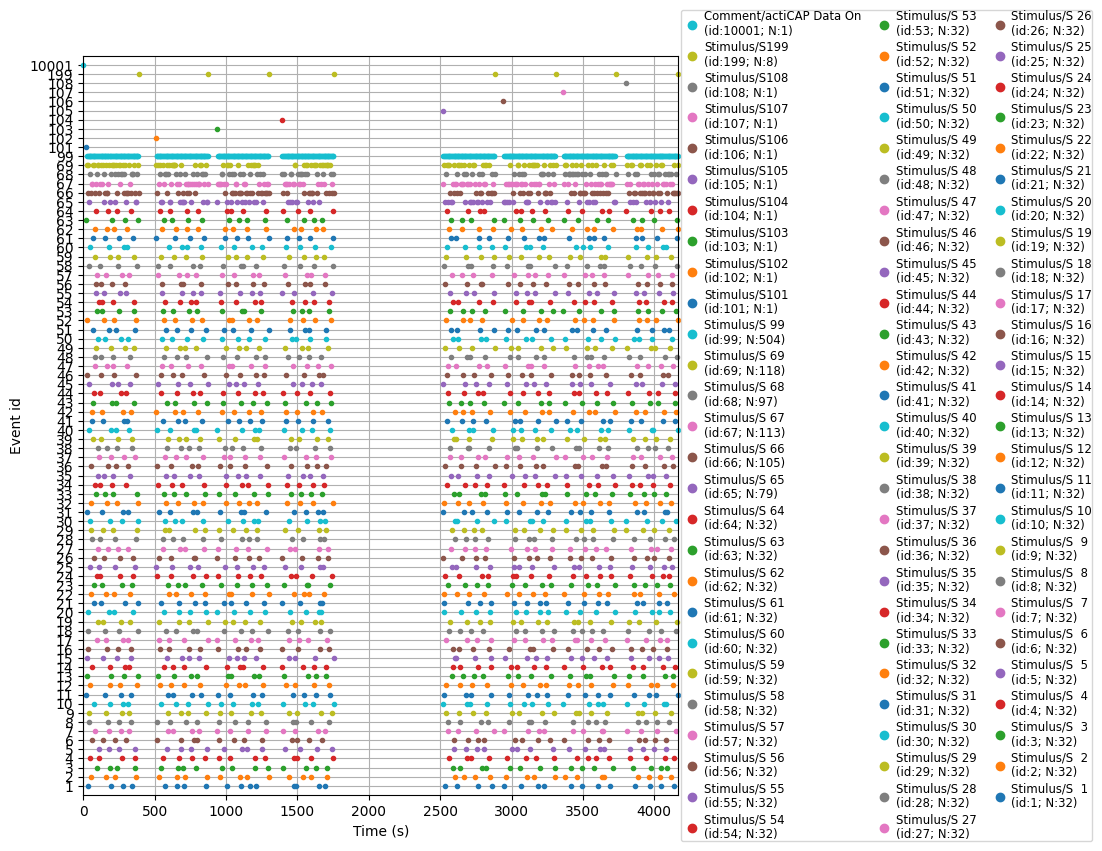

In [2]:
import mne
fig = mne.viz.plot_events(
    events_arr, event_id=event_dict, sfreq=raw.info["sfreq"], first_samp=raw.first_samp
)

In [3]:
import numpy as np

epochs_train, epochs_test= preprocessor.split_train_test()

X_train, X_test = preprocessor.scale(epochs_train.get_data(), epochs_test.get_data())

print(X_train.shape, X_test.shape) 

B_train = preprocessor.make_B(epochs_train)    # (1638, 250)
B_test  = preprocessor.make_B(epochs_test)     # (410, 250)
print(B_test.shape)
print(B_train.shape)

(819, 64, 300) (205, 64, 300)
(205, 300)
(819, 300)


Spatio-temporal: 84.9%
Computing rank from data with rank=None
    Using tolerance 34 (2.2e-16 eps * 64 dim * 2.4e+15  max singular value)
    Estimated rank (data): 64
    data: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating class=1 covariance using EMPIRICAL
Done.
Estimating class=2 covariance using EMPIRICAL
Done.
Computing rank from data with rank=None
    Using tolerance 34 (2.2e-16 eps * 64 dim * 2.4e+15  max singular value)
    Estimated rank (data): 64
    data: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating class=1 covariance using EMPIRICAL
Done.
Estimating class=2 covariance using EMPIRICAL
Done.
Computing rank from data with rank=None
    Using tolerance 35 (2.2e-16 eps * 64 dim * 2.4e+15  max singular value)
    Estimated rank (data): 64
    data: rank 64 computed from 64 data channels with 0 projectors
Reducing data rank from 64 -> 64
Estimating class=1 covariance u

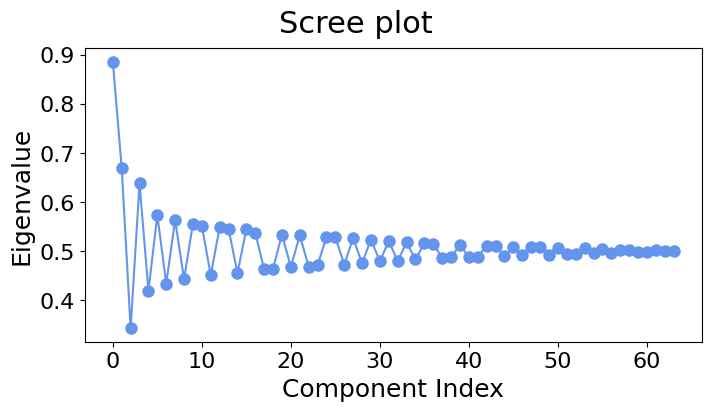

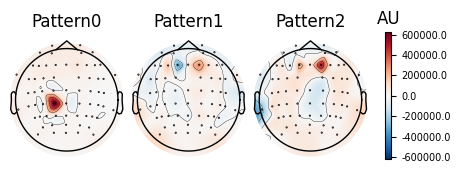

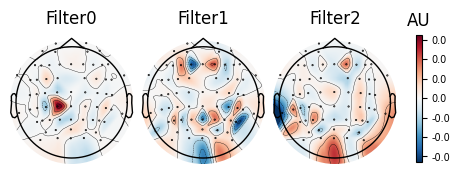

/home/bened/bachelor-thesis/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| Fitting SlidingEstimator : 300/300 [00:01<00:00,  224.70it/s]
100%|██████████| Fitting SlidingEstimator : 300/300 [00:01<00:00,  229.95it/s]
100%|██████████| Fitting SlidingEstimator : 300/300 [00:01<00:00,  228.20it/s]
100%|██████████| Fitting SlidingEstimator : 300/300 [00:02<00:00,  143.60it/s]


No projector specified for this dataset. Please consider the method self.add_proj.


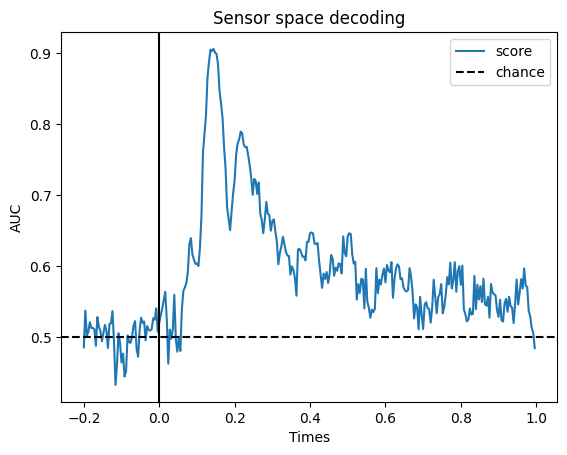

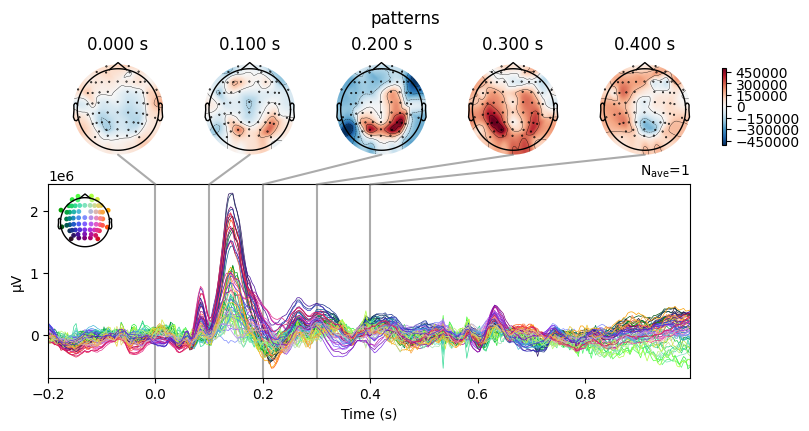

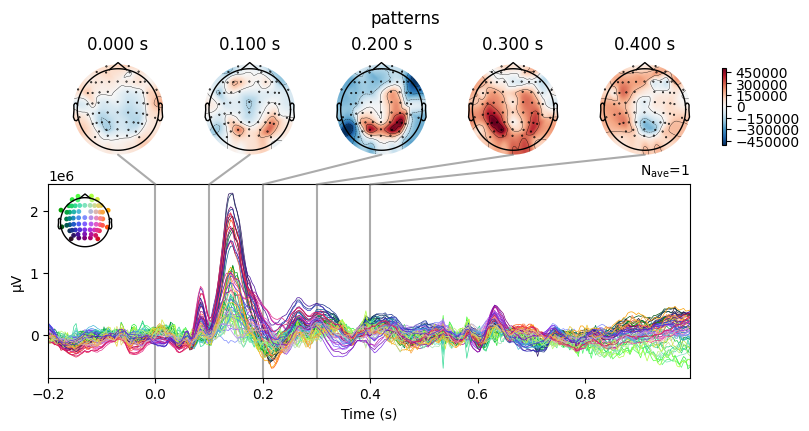

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from mne.decoding import (
    CSP,
    GeneralizingEstimator,
    LinearModel,
    Scaler,
    SlidingEstimator,
    Vectorizer,
    cross_val_multiscore,
    get_coef,
    get_spatial_filter_from_estimator,
)
import mne
import matplotlib.pyplot as plt

labels_train, category_per_epoch= preprocessor.create_labels_for_epochs(epochs_train) 

# Uses all MEG sensors and time points as separate classification
# features, so the resulting filters used are spatio-temporal
clf = make_pipeline(
    Scaler(epochs_train.info),
    Vectorizer(),
    # liblinear is faster than lbfgs
    LogisticRegression(solver="liblinear", random_state=31),
)

scores = cross_val_multiscore(clf, X_train, category_per_epoch, cv=5, n_jobs=None)

# Mean scores across cross-validation splits
score = np.mean(scores, axis=0)
print(f"Spatio-temporal: {100 * score:0.1f}%")

csp = CSP(n_components=3, norm_trace=False)
clf_csp = make_pipeline(
    csp, LinearModel(LogisticRegression(solver="liblinear", random_state=37))
)
scores = cross_val_multiscore(clf_csp, X_train, category_per_epoch, cv=5, n_jobs=None)
print(f"CSP: {100 * scores.mean():0.1f}%")

csp.fit(X_train, category_per_epoch)
spf = get_spatial_filter_from_estimator(csp, info=epochs_train.info)
spf.plot_scree()
spf.plot_patterns(components=[0, 1, 2])
spf.plot_filters(components=[0, 1, 2], scalings=1e-9)

clf = make_pipeline(
    StandardScaler(), LogisticRegression(solver="liblinear", random_state=41)
)
time_decod = SlidingEstimator(clf, n_jobs=None, scoring="roc_auc", verbose=True)
# here we use cv=3 just for speed
scores = cross_val_multiscore(time_decod, X_train, category_per_epoch, cv=3, n_jobs=None)

# Mean scores across cross-validation splits
scores = np.mean(scores, axis=0)

# Plot
fig, ax = plt.subplots()
ax.plot(epochs_train.times, scores, label="score")
ax.axhline(0.5, color="k", linestyle="--", label="chance")
ax.set_xlabel("Times")
ax.set_ylabel("AUC")  # Area Under the Curve
ax.legend()
ax.axvline(0.0, color="k", linestyle="-")
ax.set_title("Sensor space decoding")

clf = make_pipeline(
    StandardScaler(),
    LinearModel(LogisticRegression(solver="liblinear", random_state=43)),
)
time_decod = SlidingEstimator(clf, n_jobs=None, scoring="roc_auc", verbose=True)
time_decod.fit(X_train, category_per_epoch)

coef = get_coef(time_decod, "patterns_", inverse_transform=True)
evoked_time_gen = mne.EvokedArray(coef, epochs_train.info, tmin=epochs_train.times[0])
joint_kwargs = dict(ts_args=dict(time_unit="s"), topomap_args=dict(time_unit="s"))
evoked_time_gen.plot_joint(
    times=np.arange(0.0, 0.500, 0.100), title="patterns", **joint_kwargs
)
